# StackingRegressor

**Stacking** — ансамблевый метод: мы обучаем несколько базовых регрессоров на одном и том же датасете, затем строим **мета-модель**, которая учится на их *предсказаниях* (out-of-fold) предсказывать цель.  
Идея: разные модели ошибаются по-разному; комбинируя их, можно повысить устойчивость и качество.

## 1) Импорт и загрузка данных 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
df = pd.read_csv('medical_insurance (1).csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


Посмотрим выбросы по целевой переменной, для определения необходимости использования лог-преобразования:

In [6]:
import seaborn as sns

<Axes: ylabel='charges'>

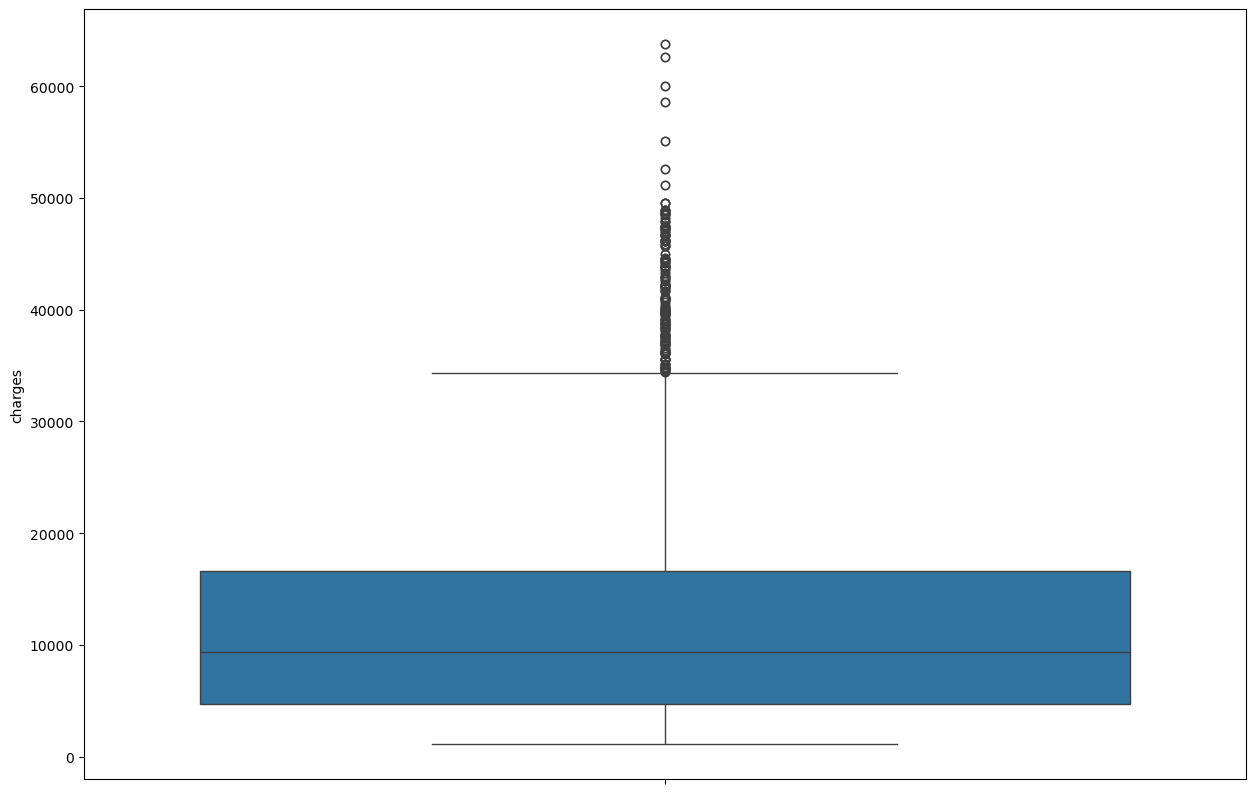

In [7]:
charges = df["charges"]
plt.figure(figsize=(15, 10))
sns.boxplot(charges)

В значениях целевой переменной есть существенное количество выбросов, соответсвенно сделаем лог преобразования.

In [8]:
    X = df.drop('charges', axis=1)
    y = np.log(df['charges'])

In [9]:
y

0       9.734176
1       7.453302
2       8.400538
3       9.998092
4       8.260197
          ...   
2767    9.056007
2768    7.610940
2769    9.708135
2770    9.980235
2771    9.195271
Name: charges, Length: 2772, dtype: float64

> Лог-преобразование часто делает распределение цены более «нормальным» и уменьшает влияние выбросов — это полезно для линейных моделей.

## 2) Выбор числовых и категориальных колонок

In [10]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [11]:
from sklearn.compose import make_column_selector

# Создаём селектор для категориальных признаков:
# выбирает все столбцы, где тип данных — object или string
cat_selector = make_column_selector(dtype_include=[object, "string"])

# Создаём селектор для числовых признаков:
# выбирает все столбцы с типом np.number (int, float и т.п.)
num_selector = make_column_selector(dtype_include=np.number)

# Получаем список категориальных колонок из датафрейма X
cat_cols = cat_selector(X)

# Получаем список числовых колонок
num_cols = num_selector(X)

# Выводим оба списка, чтобы убедиться, что типы определены корректно
cat_cols, num_cols

(['sex', 'smoker', 'region'], ['age', 'bmi', 'children'])

## 3) Препроцессинг: деревья vs линейные модели


Деревья **не требуют масштабирования** и спокойно работают с порядковыми кодами категорий.
Линейные модели требуют **One-Hot** для категорий и **стандартизации** чисел.

### 3.1 Для деревьев

In [12]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder

# Создаём кодировщик категориальных признаков для древовидных моделей.
# OrdinalEncoder преобразует категории в целые числа (0, 1, 2, ...),
# что подходит для деревьев, так как они не чувствительны к масштабу признаков.
cat_tree_processor = OrdinalEncoder(
    handle_unknown="use_encoded_value",  # как обрабатывать неизвестные категории на предсказании
    unknown_value=-1,                    # код, который будет присвоен новой категории
    encoded_missing_value=-2             # код для пропущенных значений в категориальных колонках
)

# Препроцессор числовых признаков:
# SimpleImputer заполняет пропуски средним значением.
# add_indicator=True добавляет отдельную бинарную колонку, отмечающую пропуски (0/1),
# что помогает деревьям учитывать наличие пропусков как полезный сигнал.
num_tree_processor = SimpleImputer(
    strategy="mean",
    add_indicator=True
)

# Объединяем обработки в ColumnTransformer:
# - num_tree_processor применяется ко всем числовым колонкам (num_selector)
# - cat_tree_processor применяется ко всем категориальным колонкам (cat_selector)
# Деревья допускают смешанные данные, поэтому масштабирование не требуется.
tree_preprocessor = make_column_transformer(
    (num_tree_processor, num_selector),  # числовые признаки → имьютация
    (cat_tree_processor, cat_selector)   # категориальные → OrdinalEncoder
)

# Просматриваем структуру трансформера
tree_preprocessor

,transformers,"[('simpleimputer', ...), ('ordinalencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'mean'
,fill_value,None


### 3.2 Для линейных моделей

> Важно: **сначала имьютация, потом масштабирование** — иначе скейлер увидит `NaN`.

In [13]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Создаём обработчик категориальных признаков для линейных моделей.
# OneHotEncoder превращает каждую категорию в отдельный бинарный признак (0/1),
# что важно, потому что линейные модели не должны интерпретировать категории
# как упорядоченные числа (в отличие от деревьев).
cat_linear_processor = OneHotEncoder(
    handle_unknown="ignore"  # игнорировать категории, которых не было в обучении
)

# Создаём обработчик числовых признаков.
# Последовательность операций внутри Pipeline:
num_linear_processor = make_pipeline(
    SimpleImputer(
        strategy="mean",        # заполняем пропуски средним
        add_indicator=True      # добавляем бинарный признак наличия пропуска
    ),
    StandardScaler()            # стандартизуем признаки: (x - mean) / std
)

# Объединяем числовой и категориальный препроцессоры в один ColumnTransformer:
# - num_linear_processor применяется ко всем числовым колонкам
# - cat_linear_processor применяется ко всем категориальным колонкам
linear_preprocessor = make_column_transformer(
    (num_linear_processor, num_selector),
    (cat_linear_processor, cat_selector)
)

# Показываем структуру итогового препроцессора
linear_preprocessor

,transformers,"[('pipeline', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'mean'
,fill_value,None


## 4) Базовые регрессоры (первый уровень)

Соберём три пайплайна: **LinearRegression**, **RandomForest**, **HistGradientBoosting**.

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Пайплайн №1: линейная модель с L1-регуляризацией (Lasso)
# --------------------------------------------------------
# Сначала применяется linear_preprocessor:
#   - OneHotEncoder для категорий
#   - SimpleImputer + StandardScaler для числовых
#
# Затем LassoCV — это линейная регрессия с L1-регуляризацией,
# которая может автоматически обнулять коэффициенты,
# выполняя тем самым отбор признаков.
# LassoCV самостоятельно подбирает оптимальный параметр alpha через k-fold CV.
lr_pipeline = make_pipeline(
    linear_preprocessor,
    LinearRegression()  # подбор alpha по кросс-валидации
)
lasso_pipeline

,steps,"[('columntransformer', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [22]:
# Пайплайн №2: случайный лес (Random Forest)
# ------------------------------------------
# Сначала применяется tree_preprocessor:
#   - OrdinalEncoder для категорий
#   - SimpleImputer для числовых
#
# RandomForestRegressor — ансамбль деревьев решений,
# устойчивый к выбросам, нелинейностям и взаимодействиям признаков.
# n_estimators=400 означает 400 деревьев → более стабильные предсказания.
rf_pipeline = make_pipeline(
    tree_preprocessor,
    RandomForestRegressor(
        n_estimators=400,     # количество деревьев в ансамбле
        random_state=42       # фиксируем случайность для воспроизводимости
    )
)
rf_pipeline

,steps,"[('columntransformer', ...), ('randomforestregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('simpleimputer', ...), ('ordinalencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
# Пайплайн №3: градиентный бустинг по гистограммам
# -------------------------------------------------
# HistGradientBoostingRegressor — современный бустинговый алгоритм,
# работает быстрее классического GradientBoosting,
# поддерживает пропуски и выдаёт высокое качество на табличных данных.
# Здесь также используем tree_preprocessor, потому что деревьям
# не нужны масштабированные признаки.
gbdt_pipeline = make_pipeline(
    tree_preprocessor,
    HistGradientBoostingRegressor(
        random_state=0   # фиксируем сид генератора
    )
)
gbdt_pipeline

,steps,"[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('simpleimputer', ...), ('ordinalencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 5) StackingRegressor (второй уровень / мета-модель)

Мета-модель — **RidgeCV** (линейная с L2). В `StackingRegressor` out-of-fold предсказания базовых моделей строятся с кросс-валидацией (`cv`). По умолчанию `cv=None` → используется 5-fold.

In [24]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV

# Список базовых моделей (первого уровня стэкинга).
# Каждая запись — кортеж: ("имя модели", pipeline).
# Важный момент: обязательно передавать пайплайны,
# чтобы каждая модель получала корректно предобработанные данные.
estimators = [
    ("Random Forest", rf_pipeline),
    ("LinearRegression", lr_pipeline),
    ("Gradient Boosting", gbdt_pipeline),
]

# Создаём стэкинг-регрессор:
stacking_regressor = StackingRegressor(
    estimators=estimators,      # базовые регрессоры, которые создают мета-признаки
    final_estimator=RidgeCV(),  # мета-модель (второй уровень), обучается на предсказаниях базовых моделей
                                # RidgeCV подбирает силу регуляризации alpha автоматически (через CV)
    cv=5,                       # 5-fold cross-validation для генерации out-of-fold предсказаний
                                # (исключает утечку данных при обучении мета-модели)
    passthrough=False           # если True → в мета-модель передаются и исходные признаки X
                                # здесь используем False, чтобы мета-модель работала ТОЛЬКО с
                                # предсказаниями базовых моделей (классический stacking)
)

# Просматриваем структуру итогового ансамбля
stacking_regressor

,estimators,"[('Random Forest', ...), ('LinearRegression', ...), ...]"
,final_estimator,RidgeCV()
,cv,5
,n_jobs,None
,passthrough,False
,verbose,0
,transformers,"[('simpleimputer', ...), ('ordinalencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None


## 6) Оценка качества и визуализация

Сравним одиночные модели и стэкинг по **R²** и **MAE** с кросс-валидацией; построим диаграммы «истинное vs предсказанное».

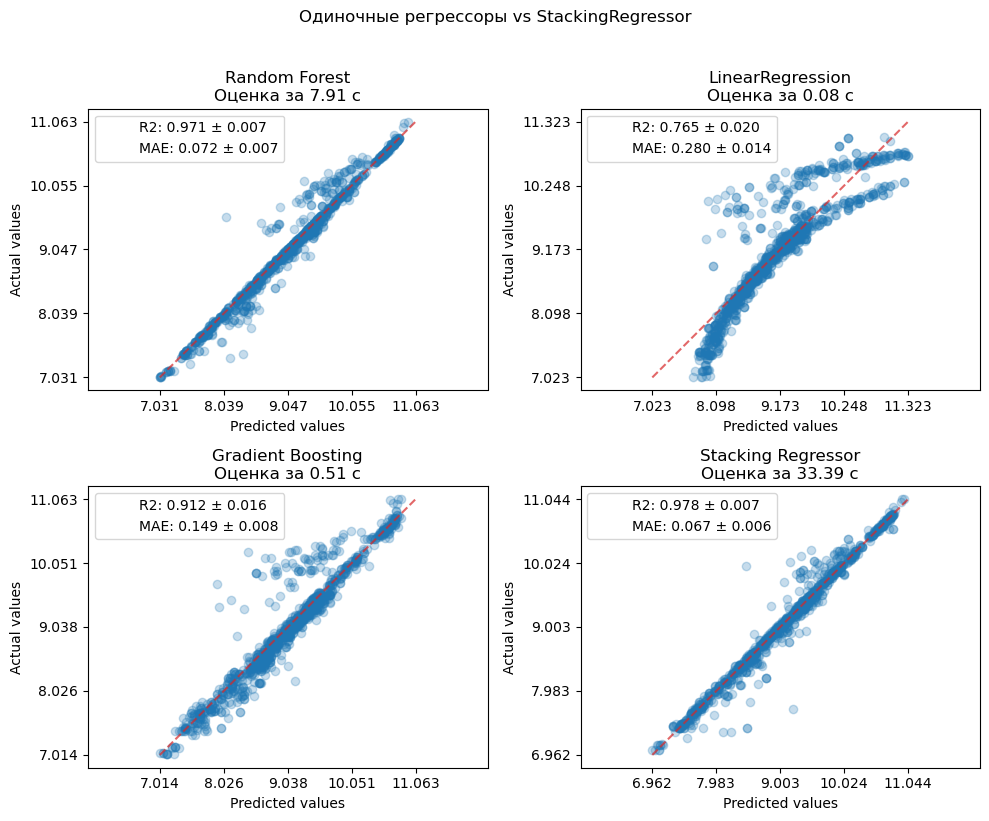

In [25]:
import time
from sklearn.metrics import PredictionErrorDisplay
from sklearn.model_selection import cross_val_predict, cross_validate

# Создаём сетку из 4 подграфиков (2x2) для сравнения трёх моделей + стэкинга
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs = np.ravel(axs)  # разворачиваем массив осей в одномерный список

# Собираем все модели: базовые (estimators) + стэкинг
all_estimators = estimators + [("Stacking Regressor", stacking_regressor)]

# Цикл по всем моделям и соответствующим осям графиков
for ax, (name, est) in zip(axs, all_estimators):
    # Словарь метрик: человеко-читаемое имя → строковый код для scikit-learn
    scorers = {"R2": "r2", "MAE": "neg_mean_absolute_error"}

    # Засекаем время, чтобы оценить, сколько занимает кросс-валидация
    start = time.time()
    cv_res = cross_validate(
        est, X, y,
        scoring=list(scorers.values()),  # передаем список метрик в виде ['r2', 'neg_mean_absolute_error']
        n_jobs=-1,                       # использовать все доступные ядра
        cv=5,                            # 5-fold кросс-валидация
        verbose=0
    )
    elapsed = time.time() - start  # общее время оценки модели

    # Строим out-of-fold предсказания для каждого объекта.
    # Важно: каждое предсказание делается моделью, которая не видела этот объект в обучении.
    y_pred = cross_val_predict(
        est, X, y,
        n_jobs=-1,
        cv=5,
        verbose=0
    )

    # Формируем компактное текстовое резюме метрик:
    # среднее значение ± стандартное отклонение по фолдам
    summary = {
        k: f"{np.abs(np.mean(cv_res[f'test_{v}'])):.3f} ± {np.std(cv_res[f'test_{v}']):.3f}"
        for k, v in scorers.items()
    }

    # Строим график "истинное значение vs предсказанное"
    # Идеал — точки лежат вдоль красной диагонали.
    display = PredictionErrorDisplay.from_predictions(
        y_true=y,
        y_pred=y_pred,
        kind="actual_vs_predicted",          # формат: фактические значения по оси X, предсказанные по оси Y
        ax=ax,
        scatter_kwargs={"alpha": 0.25, "color": "tab:blue"},  # настройки точек
        line_kwargs={"color": "tab:red"},                      # линия идеальных предсказаний
    )

    # Заголовок подграфика: имя модели + время оценки
    ax.set_title(f"{name}\nОценка за {elapsed:.2f} с")

    # Добавляем метрики в легенду, используя "пустые" линии (чтобы просто вывести текст)
    for m, s in summary.items():
        ax.plot([], [], " ", label=f"{m}: {s}")
    ax.legend(loc="upper left")

# Общий заголовок для всей фигуры
plt.suptitle("Одиночные регрессоры vs StackingRegressor", y=1.02)

# Уплотняем расположение графиков, чтобы ничего не налезало
plt.tight_layout()
plt.show()

> Чем ближе точки к красной диагонали на графике, тем качественней предсказания. В легенде — средние метрики по фолдам (R² выше — лучше; MAE ниже — лучше). Стэкинг обычно сопоставим с лучшей одиночной моделью и нередко слегка улучшает её — но стоит дороже по времени.

Вывод: При построении трех моделей регрессии и модели стэкинга, можно сказать о том, что полученная модель стекинга для наших данных действительно является наилучшей, с коэффициентов детерминации очень близким к 1 (0,978), что говорит о том, что модель является точной, так как эмпирические значения, полученные по модели, совпадают с фактическими. Средняя квадратическая ошибка по модели стэкинга также является наименьшей (0,067). Можно также отметить, что модели Random Forest и Gradient Boosting, сами по себе показали хорошие результаты и могут использоваться для прогнозирования целевой переменной charges. Модель линейной регрессии же показала результаты значительно хуже, коэффициент детерминации = 0,765, в данном случае модель является наихудшей.